# 04 - Churn: who leaves, why, and who is at risk now

**Question.** How many customers stop buying, which behaviours go with churn, and which
current customers should the business act on first?

**Churn definition.** The business has no subscriptions, so churn has to be inferred from
silence. A customer counts as churned if their last order is older than the 90th
percentile of all observed gaps between consecutive orders, measured at 1 January 2026.
In words: they have been quiet for longer than 9 in 10 real repeat purchases take.
Customers whose first order is more recent than that threshold are labelled *too new to
judge* and left out of churn rates, rather than being counted as safely active.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().resolve().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import metrics, plots
from src.common import load_config, project_path

cfg = load_config()
conn = metrics.open_db(cfg)
FIGURES = project_path(cfg["paths"]["figures_dir"])
pd.set_option("display.float_format", "{:,.2f}".format)
plots.apply_style()

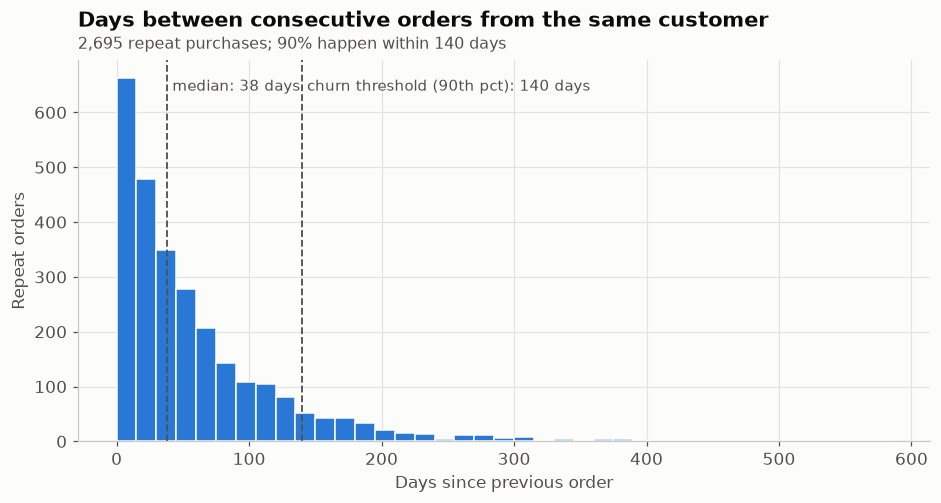

In [2]:
customers, rule = metrics.build_customer_table(conn, cfg)
gaps = metrics.run_query(conn, "order_revenue")["days_since_previous_order"].dropna()
threshold = rule["threshold_days"]

fig, ax = plots.new_figure(10, 4.5)
ax.hist(gaps, bins=range(0, int(gaps.max()) + 15, 15), color=plots.SERIES[0], edgecolor=plots.SURFACE, linewidth=1)
for value, label in [(rule["median_gap_days"], "median"), (threshold, "churn threshold (90th pct)")]:
    ax.axvline(value, color=plots.TEXT_SECONDARY, linewidth=1.2, linestyle="--")
    ax.text(value, ax.get_ylim()[1] * 0.92, f" {label}: {value:.0f} days", color=plots.TEXT_SECONDARY, fontsize=10)
plots.set_titles(ax, "Days between consecutive orders from the same customer",
                 f"{rule['repeat_gaps']:,} repeat purchases; 90% happen within {threshold} days")
ax.set_xlabel("Days since previous order")
ax.set_ylabel("Repeat orders")
plots.save_figure(fig, FIGURES / "04_repeat_gap_distribution.png")
plt.show()

In [3]:
status = customers["churn_status"].value_counts()
judged = customers[customers["churn_status"] != "too_new"]
print(status.to_string())
print(f"Churn rate among judgeable buyers: {judged['churned'].mean():.1%} of {len(judged)}")

churn_status
churned    841
active     198
too_new    169
Churn rate among judgeable buyers: 80.9% of 1039


### Does the definition find real churners?

The generator recorded the month each customer actually went inactive. This truth is not
available in real data, but here it can test the definition.

In [4]:
truth = pd.read_csv(project_path(cfg["paths"]["customer_truth"]))[["customer_id", "churn_month"]]
check = judged.merge(truth, on="customer_id")
check["truly_inactive"] = check["churn_month"].notna()
display(pd.crosstab(check["churned"], check["truly_inactive"], rownames=["labelled churned"], colnames=["truly inactive"]))
print(f"Agreement with ground truth: {(check['churned'] == check['truly_inactive']).mean():.1%}")

truly inactive,False,True
labelled churned,,
False,165,33
True,50,791


Agreement with ground truth: 92.0%


## Who churns

In [5]:
metrics.churn_rate_by(customers, "buyer_type").style.format({"churn_rate": "{:.0%}", "lift": "{:.2f}"})

,customers,churn_rate,lift
buyer_type,,,
one order,468,100%,1.24
repeat,571,65%,0.81


Every judgeable one-order customer is churned by definition: they never came back. The
real question is therefore twofold:

1. How to get a second order.
2. Among customers who did come back, what predicts leaving.

The driver analysis below uses repeat buyers only. Including one-order buyers would make
discount share (always 0% or 100% for one order) and return rate look predictive for the
wrong reason.

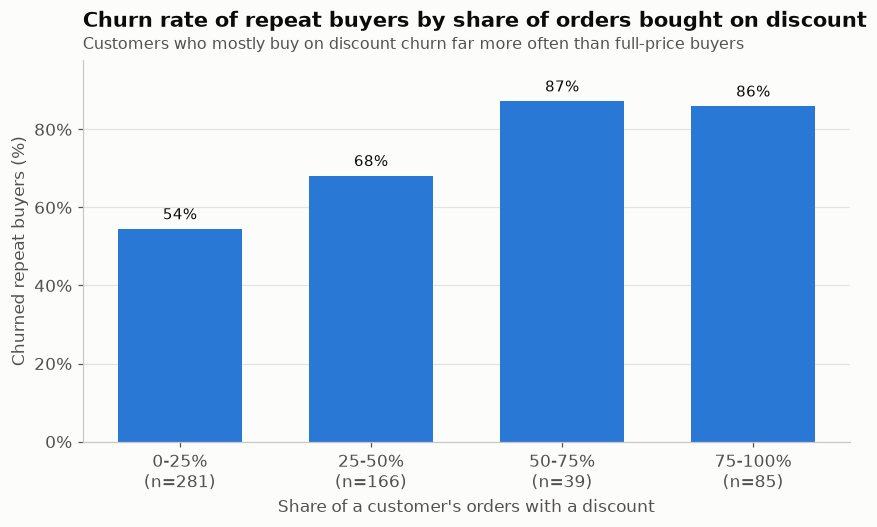

,customers,churn_rate,lift
discount_band,,,
0-25%,281,0.54,0.83
25-50%,166,0.68,1.04
50-75%,39,0.87,1.33
75-100%,85,0.86,1.31


In [6]:
repeat = customers[customers["orders"] > 1]


def churn_bar(column: str, title: str, subtitle: str, xlabel: str, filename: str, horizontal: bool = False) -> pd.DataFrame:
    """Bar chart of repeat-buyer churn rate per group, with group sizes in the labels."""
    table = metrics.churn_rate_by(repeat, column)
    if not horizontal:
        table = table.sort_index()
    labels = [f"{name}\n(n={n})" for name, n in zip(table.index, table["customers"])]
    fig, ax = plots.new_figure(9, 4.5)
    plots.bar_chart(ax, labels, table["churn_rate"].to_numpy(), value_format="{:.0%}", horizontal=horizontal)
    plots.format_axis(ax, "x" if horizontal else "y", "pct")
    plots.set_titles(ax, title, subtitle)
    if horizontal:
        ax.set_xlabel("Churned repeat buyers (%)")
    else:
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Churned repeat buyers (%)")
    plots.save_figure(fig, FIGURES / filename)
    plt.show()
    return table


churn_bar("discount_band", "Churn rate of repeat buyers by share of orders bought on discount",
          "Customers who mostly buy on discount churn far more often than full-price buyers",
          "Share of a customer's orders with a discount", "04_churn_by_discount.png")

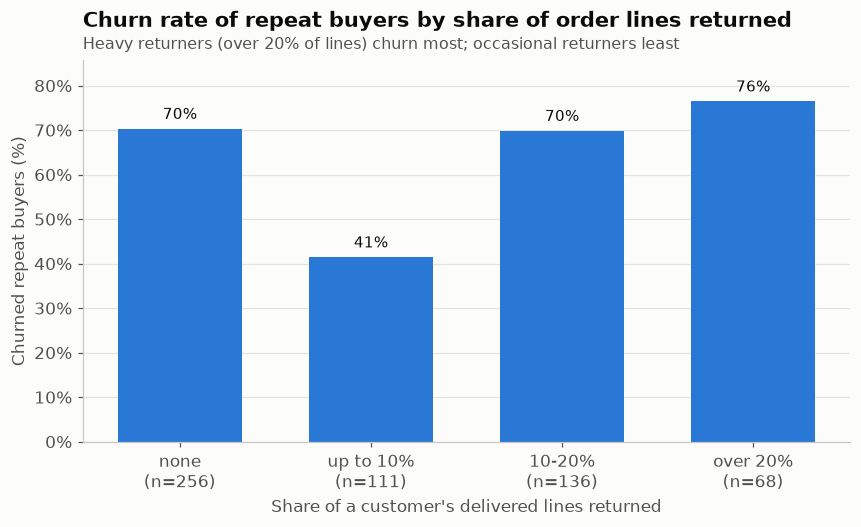

,customers,churn_rate,lift
return_band,,,
none,256,0.70,1.08
up to 10%,111,0.41,0.63
10-20%,136,0.70,1.07
over 20%,68,0.76,1.17


In [7]:
churn_bar("return_band", "Churn rate of repeat buyers by share of order lines returned",
          "Heavy returners (over 20% of lines) churn most; occasional returners least",
          "Share of a customer's delivered lines returned", "04_churn_by_returns.png")

The return pattern is U-shaped. Customers with *no* returns churn more than occasional
returners because they tend to have fewer orders and therefore fewer chances to return
anything. The clear signal is the top band: buyers returning over a fifth of their lines
churn most.

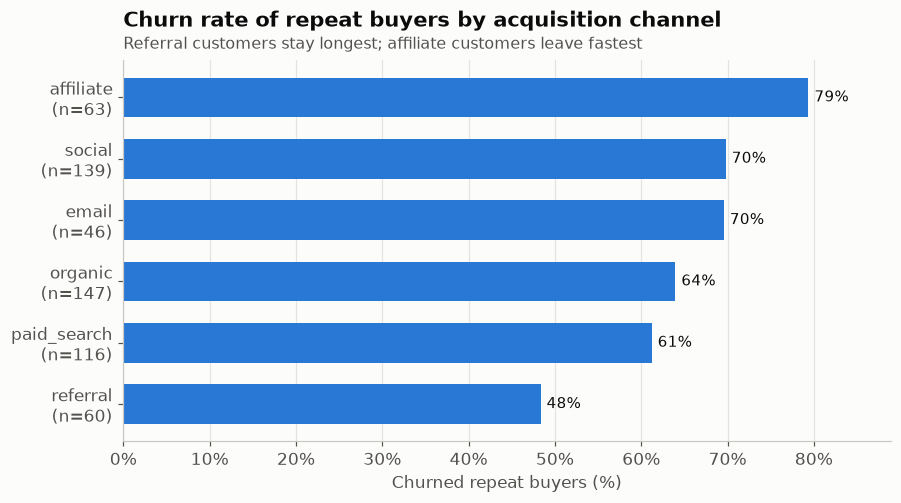

,customers,churn_rate,lift
acquisition_channel,,,
affiliate,63,0.79,1.21
social,139,0.70,1.07
email,46,0.70,1.06
organic,147,0.64,0.98
paid_search,116,0.61,0.94
referral,60,0.48,0.74


In [8]:
churn_bar("acquisition_channel", "Churn rate of repeat buyers by acquisition channel",
          "Referral customers stay longest; affiliate customers leave fastest",
          "", "04_churn_by_channel.png", horizontal=True)

In [9]:
display(metrics.churn_rate_by(repeat, "division").style.format({"churn_rate": "{:.0%}", "lift": "{:.2f}"}))
display(metrics.churn_rate_by(repeat, "gender").style.format({"churn_rate": "{:.0%}", "lift": "{:.2f}"}))

,customers,churn_rate,lift
division,,,
Rangpur,39,77%,1.18
Rajshahi,48,73%,1.12
Barishal,16,69%,1.05
Dhaka,261,65%,1.00
Mymensingh,20,65%,1.00
Chattogram,96,62%,0.96
Sylhet,42,62%,0.95
Khulna,49,57%,0.87


,customers,churn_rate,lift
gender,,,
Female,253,68%,1.03
Male,306,64%,0.98
Unknown,12,58%,0.89


Division and gender show no consistent pattern; the differences are within what small
groups produce by chance. Churn is behavioural, not geographic.

## At-risk customers to act on now

At risk = active, but silent for longer than the median repeat gap without crossing the
churn threshold. These are the customers a win-back message can still reach, ranked by
past revenue.

In [10]:
names = pd.read_sql_query("SELECT customer_id, full_name FROM customers", conn)
at_risk = customers[customers["at_risk"]].merge(names, on="customer_id").sort_values("revenue", ascending=False)
print(f"At-risk customers: {len(at_risk)}, past revenue {at_risk['revenue'].sum():,.0f} BDT "
      f"({at_risk['revenue'].sum() / customers['revenue'].sum():.1%} of all revenue)")
at_risk[["customer_id", "full_name", "division", "acquisition_channel", "orders", "revenue",
         "recency_days", "rfm_segment"]].head(15)

At-risk customers: 91, past revenue 3,024,887 BDT (16.9% of all revenue)


,customer_id,full_name,division,acquisition_channel,orders,revenue,recency_days,rfm_segment
6,286,বাঁধন প্রধান,Khulna,organic,27,"193,195.00",44,Champions
1,99,এনামুল আলম,Rajshahi,organic,26,"132,345.00",50,Champions
16,575,বাসির পাল,Dhaka,organic,23,"127,030.00",42,Champions
7,353,অর্না বসু,Chattogram,paid_search,23,"125,940.00",129,Champions
9,380,মাধুরী হুরাইরা,Dhaka,organic,19,"112,620.00",46,Champions
17,583,অর্পিতা আবদুল্লাহ,Chattogram,referral,17,"107,475.00",121,Champions
2,182,কবিতা কান্ত,Dhaka,paid_search,15,"104,580.00",48,Champions
8,355,সৌম্য যাদব,Dhaka,social,24,"94,396.00",130,Champions
18,631,শাওন ঠাকুর,Sylhet,referral,11,"77,428.00",92,Champions
50,1031,মনোজ শুক্লা,Dhaka,social,9,"71,552.00",53,Champions


## Findings

- **The churn line is 140 days.** 90% of repeat purchases happen within 140 days of the
  previous one. The median gap is 38 days.
- **The definition works.** The label agrees with the generator's hidden churn truth for
  92% of judgeable customers.
- **The biggest leak is the second order.** 45% of judgeable buyers (468 of 1,039) never
  ordered again. Repeat buyers churn at 65%, compared with 100% for one-order buyers by
  definition.
- **Drivers, among repeat buyers:**
  - *Discount dependence:* buyers with over half their orders discounted churn at 86-87%,
    against 54% for those with a quarter or fewer.
  - *Heavy returns:* buyers returning over 20% of lines churn at 76%, against 41% for
    those returning up to 10%.
  - *Acquisition channel:* referral 48% against affiliate 79%.
- **No effect:** geography and gender show no consistent difference.
- **Act now:** 91 active customers have gone quiet for longer than a typical repeat gap.
  They hold 3.0M BDT of past revenue (16.9% of the total), and most are Champions. They
  are listed in `reports/summary.xlsx`.

These are associations in observational data, not proven causes. For example, discounts
may attract customers who were never going to stay, rather than discounts making customers
leave. Telling the two apart needs an experiment, such as holding back discounts for a
random group.